In [63]:
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [64]:
data = pd.read_csv('dataset_timnas.csv')

text_col = 'text_clean' if 'text_clean' in data.columns else 'full_text'

data = data.dropna(subset=[text_col])
data = data[data[text_col].astype(str).str.strip() != '']
data = data[data[text_col].astype(str).str.lower() != 'nan']
data = data.reset_index(drop=True)

print("Total dokumen:", len(data))
print("Kolom yang dipakai:", text_col)


Total dokumen: 635
Kolom yang dipakai: text_clean


In [65]:
stopword_id = set("""
yang dan di ke dari untuk pada dengan adalah ini itu akan atau juga karena
sebagai oleh dalam telah sudah saya kamu dia kami kita mereka anda nya ku mu
tidak bukan belum jangan ada tak bisa dapat harus saja lebih sangat agar
oleh terhadap antara setelah sebelum saat ketika jika maka bahwa para
""".split())

stopword_en = set("""
the a an and or of to in on for with is are was were be been being this that
these those it its as at by from have has had do does did but if then so
""".split())

slang_dict = {
    'yg':'yang','dgn':'dengan','utk':'untuk','tdk':'tidak','gak':'tidak',
    'ga':'tidak','gk':'tidak','bgt':'banget','aja':'saja','kalo':'kalau',
    'klo':'kalau','udh':'sudah','udah':'sudah','tp':'tapi','tpi':'tapi',
    'gw':'saya','gue':'saya','jg':'juga','dr':'dari'
}

def normalize_slang(t):
    return ' '.join([slang_dict.get(w, w) for w in t.split()])

def remove_stopwords(t):
    return ' '.join([w for w in t.split()
                     if w not in stopword_id and w not in stopword_en and len(w) > 2])

data['text_final'] = (data[text_col].astype(str)
                      .str.lower()
                      .apply(normalize_slang)
                      .apply(remove_stopwords))

data = data[data['text_final'].str.strip() != ''].reset_index(drop=True)

In [66]:
vectorizer = TfidfVectorizer(
    stop_words=list(stopword_id | stopword_en),
    max_features=1000,
    ngram_range=(1, 2),
    min_df=2
)
X = vectorizer.fit_transform(data['text_final'])
print("Shape TF-IDF:", X.shape)

Shape TF-IDF: (635, 1000)


In [67]:
true_k = 3
model = KMeans(n_clusters=true_k, random_state=42, n_init=10)
data['cluster'] = model.fit_predict(X)

print("\nJumlah postingan per cluster:")
print(data['cluster'].value_counts().sort_index())


Jumlah postingan per cluster:
cluster
0     49
1     50
2    536
Name: count, dtype: int64


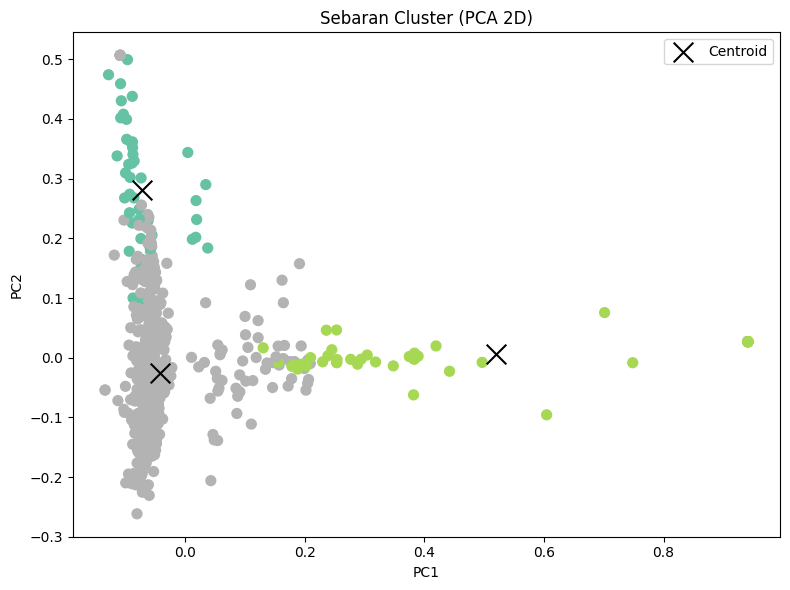

In [68]:
pca = PCA(n_components=2, random_state=0)
reduced = pca.fit_transform(X.toarray())
centers = pca.transform(model.cluster_centers_)

plt.figure(figsize=(8, 6))
plt.scatter(reduced[:, 0], reduced[:, 1], c=data['cluster'], cmap='Set2', s=50)
plt.scatter(centers[:, 0], centers[:, 1], marker='x', s=200, c='black', label='Centroid')
plt.title('Sebaran Cluster (PCA 2D)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

In [69]:
order_centroids = model.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

top_words = {}
for i in range(true_k):
    top_words[i] = [terms[ind] for ind in order_centroids[i, :5]]
    print(f"\nCluster {i} — top 5: {top_words[i]}")


Cluster 0 — top 5: ['fifa', 'asean', 'asean cup', 'fifa asean', 'cup']

Cluster 1 — top 5: ['garuda', 'jembatan', 'they', 'pembangunan jembatan', 'pembangunan']

Cluster 2 — top 5: ['timnas', 'timnasday', 'pssi', 'indonesia', 'pemain']


In [70]:
# melihat isi tiap cluster
for c in range(true_k):
    subset = data[data['cluster'] == c]
    contoh = subset[text_col].head(3).tolist()

    print(f"\n{'='*50}")
    print(f"CLUSTER {c} — {len(subset)} postingan")
    print(f"Kata dominan: {top_words[c]}")
    print('-'*50)
    for i, t in enumerate(contoh, 1):
        print(f"{i}. {str(t)[:200]}")
    print()


CLUSTER 0 — 49 postingan
Kata dominan: ['fifa', 'asean', 'asean cup', 'fifa asean', 'cup']
--------------------------------------------------
1. di bawah arahan john herdman timnas indonesia sukses mengakhiri puasa gelar senior dengan menjuarai fifa asean cup 2026 usai mengalahkan thailand lewat adu penalti dramatis melihat permainan dari skua
2. salah satu garuda abroad kebanggaan kita calvin verdonk tampak mendapat sambutan hangat dari lille usai kembali dari fifa asean cup 2026 ia ikut dalam sesi pre match press conference dan menyatakan si
3. keberhasilan timnas indonesia menjuarai fifa asean cup 2026 membuat pasukan garuda melengkapi daftar pemenang trofi dari beberapa turnamen resmi yang diadakan oleh fifa


CLUSTER 1 — 50 postingan
Kata dominan: ['garuda', 'jembatan', 'they', 'pembangunan jembatan', 'pembangunan']
--------------------------------------------------
1. ibarat capo ultras garuda tahun 98
2. the garuda vishnu statue visible for miles in bali is a sight to behold hi